## Q2: Randomized sketching for least squares


### Loading the data

In [45]:
import numpy as np
import matplotlib.pyplot as plt
import time

random_state = np.random.default_rng(0) # random number generator

# data_path = r'C:\Users\HP\Desktop\dsc q2'
# D = np.load(data_path + r'\D.npy')
# y = np.load(data_path + r'\y.npy')
D = np.load('D.npy')
y = np.load('y.npy')
D = D.astype(float)
y = y.astype(float).flatten()
num_rows, num_features = D.shape

assert D.shape[0] == y.size
assert np.all(np.isfinite(D))
assert np.all(np.isfinite(y))

print("Number of rows:", num_rows)
print("Number of features:", num_features)

Number of rows: 494021
Number of features: 116


In [46]:
def countsketch(D, y, m, rng):
    rows, cols = D.shape

    # assign each row to a random bucket with a random sign
    bucket_ids = rng.integers(0, m, rows)
    random_signs = rng.choice([-1, 1], size=rows)

    #initialize the matrix and vector
    sketched_D = np.zeros((m, cols))
    sketched_y = np.zeros(m)

    
    batch_size = 50000

    for i in range(0, rows, batch_size):
        j = min(i + batch_size, rows)
        row_indices = bucket_ids[i:j]
        signed_rows = D[i:j] * random_signs[i:j, None]
        signed_labels = y[i:j] * random_signs[i:j]

        np.add.at(sketched_D, row_indices, signed_rows)
        np.add.at(sketched_y, row_indices, signed_labels)

    return sketched_D, sketched_y


def loss(D, y, a):
    errors = D @ a - y
    return errors @ errors

## Q2(a) 


In [47]:
# compute the least-squares solution on the complete dataset
t0 = time.perf_counter()
b = np.linalg.lstsq(D, y, rcond=None)[0]
elapsed = time.perf_counter() - t0

# evaluate
baseline_loss = loss(D, y, b)
matrix_rank = np.linalg.matrix_rank(D)

print(f"full data loss: {baseline_loss:.4f}")
print(f"computation time: {elapsed:.3f} seconds")
print(f"rank of D: {matrix_rank}")
print(f"number of features: {D.shape[1]}")

full data loss: 2949.7888
computation time: 3.809 seconds
rank of D: 113
number of features: 116


## Q2(b) 

In [48]:
sketch_sizes = [50, 100, 200, 500, 1000, 2000, 5000]

avg_ratios = []
lowest_ratios = []
highest_ratios = []
avg_sketch_losses = []
avg_original_losses = []
avg_runtimes = []

for sketch_dim in sketch_sizes:
    trial_ratios = []
    trial_sketch_losses = []
    trial_original_losses = []
    trial_times = []

    for _ in range(5):
        t0 = time.perf_counter()

        sketched_D, sketched_y = countsketch(D, y, sketch_dim, rng)
        approx_solution = np.linalg.lstsq(
            sketched_D, sketched_y, rcond=None
        )[0]

        trial_times.append(time.perf_counter() - t0)

        loss_on_data = loss(D, y, approx_solution)
        loss_on_sketch = np.sum((sketched_D @ approx_solution - sketched_y) ** 2)

        trial_original_losses.append(loss_on_data)
        trial_sketch_losses.append(loss_on_sketch)
        trial_ratios.append(loss_on_data / baseline_loss)

    avg_ratios.append(np.mean(trial_ratios))
    lowest_ratios.append(np.min(trial_ratios))
    highest_ratios.append(np.max(trial_ratios))
    avg_original_losses.append(np.mean(trial_original_losses))
    avg_sketch_losses.append(np.mean(trial_sketch_losses))
    avg_runtimes.append(np.mean(trial_times))

    print(
        f"m={sketch_dim:4d} | "
        f"original loss={np.mean(trial_original_losses):.4f} | "
        f"ratio={np.mean(trial_ratios):.4f} "
        f"(min={np.min(trial_ratios):.4f}, "
        f"max={np.max(trial_ratios):.4f}) | "
        f"sketched loss={np.mean(trial_sketch_losses):.4f}"
    )

m=  50 | original loss=10255.3915 | ratio=3.4767 (min=2.7072, max=3.8497) | sketched loss=0.0000
m= 100 | original loss=48274.8040 | ratio=16.3655 (min=8.7153, max=23.9522) | sketched loss=0.0000
m= 200 | original loss=6802.4171 | ratio=2.3061 (min=2.0817, max=2.5486) | sketched loss=1287.4543
m= 500 | original loss=3910.7451 | ratio=1.3258 (min=1.2268, max=1.3858) | sketched loss=2328.2893
m=1000 | original loss=3294.3235 | ratio=1.1168 (min=1.1015, max=1.1387) | sketched loss=2605.7169
m=2000 | original loss=3126.7578 | ratio=1.0600 (min=1.0467, max=1.0680) | sketched loss=2741.7461
m=5000 | original loss=3018.3169 | ratio=1.0232 (min=1.0200, max=1.0269) | sketched loss=2920.2701


The table reports the mean original-data loss, mean loss ratio, minimum and maximum ratio, and mean sketched loss across the five runs

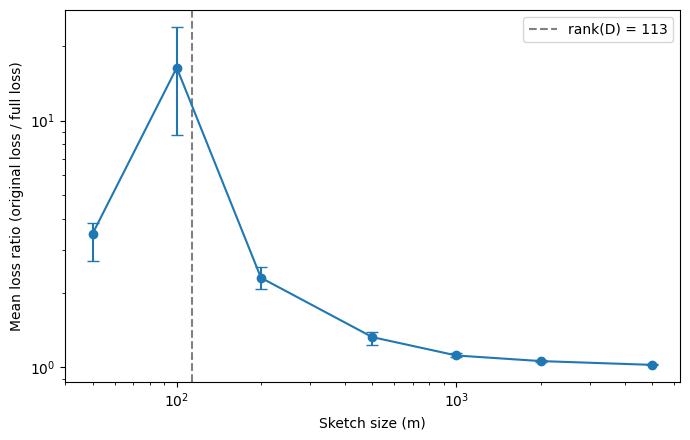

In [49]:
avg_ratios = np.array(avg_ratios)
lowest_ratios = np.array(lowest_ratios)
highest_ratios = np.array(highest_ratios)

plt.figure(figsize=(7, 4.5))

plt.errorbar(
    sketch_sizes,
    avg_ratios,
    yerr=[
        avg_ratios - lowest_ratios,
        highest_ratios - avg_ratios
    ],
    fmt='o-',
    capsize=4
)

plt.axvline(
    matrix_rank,
    linestyle='--',
    color='gray',
    label=f'rank(D) = {matrix_rank}'
)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Sketch size (m)')
plt.ylabel('Mean loss ratio (original loss / full loss)')
plt.legend()
plt.tight_layout()
plt.savefig('q2b_loss_ratio.png', dpi=150)
plt.show()

### Answer

As the sketch size increases, the solution generally gets better. A larger sketch gives a solution that is closer to the one obtained using the full dataset.

The rank of the original matrix is 113. When m is below this value, the sketched system has fewer rows, so it can fit the sketched data almost perfectly. This is why the sketched loss is close to zero for m = 50 and 100.

When m is above 113, the sketched system has more rows, and the sketched loss generally increases. At the same time, the solution gives a better fit on the original dataset, which is reflected in the loss ratio getting closer to 1 as m increases.


## Q2(c) 

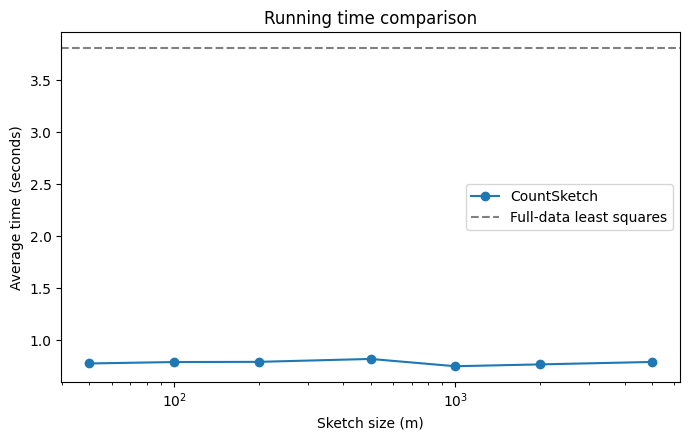

m=  50: average time=0.7782 seconds
m= 100: average time=0.7919 seconds
m= 200: average time=0.7937 seconds
m= 500: average time=0.8216 seconds
m=1000: average time=0.7517 seconds
m=2000: average time=0.7693 seconds
m=5000: average time=0.7927 seconds
Full-data solve time: 3.8088 seconds


In [50]:
plt.figure(figsize=(7, 4.5))

plt.plot(
    sketch_sizes,
    avg_runtimes,
    'o-',
    label='CountSketch'
)

plt.axhline(
    elapsed,
    linestyle='--',
    color='gray',
    label='Full-data least squares'
)

plt.xscale('log')
plt.xlabel('Sketch size (m)')
plt.ylabel('Average time (seconds)')
plt.title('Running time comparison')
plt.legend()
plt.tight_layout()

plt.savefig('q2c_runtime.png', dpi=150)
plt.show()

# average times
for sketch_dim, avg_time in zip(sketch_sizes, avg_runtimes):
    print(f"m={sketch_dim:4d}: average time={avg_time:.4f} seconds")

print(f"Full-data solve time: {elapsed:.4f} seconds")

### Answer 

The time does not change much as sketch size increases. The full data least squares solution takes more time than the time taken by CountSketch for all the sketch sizes tested which shows that CountSketch is faster than solving the least-squares problem on the full dataset, even after including the time to generate the sketch, form SD and Sy, and compute the solution.

## Q2(d) 

m=50: mean=0.9989, standard deviation=0.1755
m=500: mean=0.9995, standard deviation=0.0562
m=5000: mean=0.9997, standard deviation=0.0210


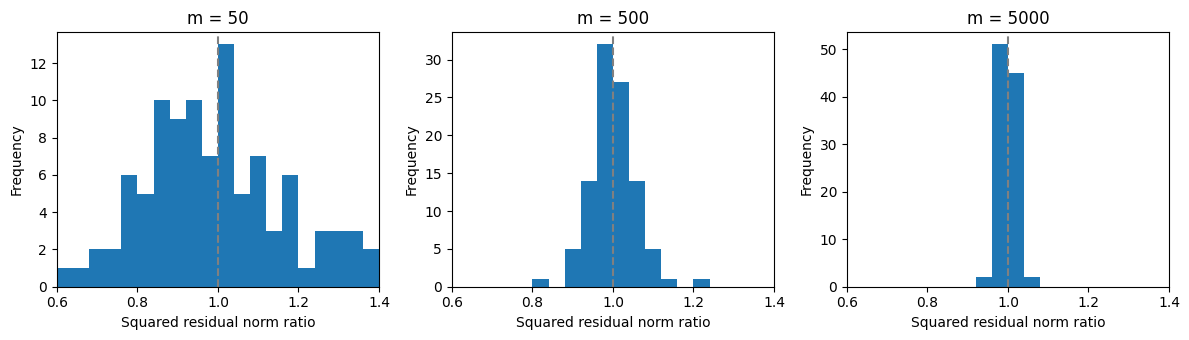

In [51]:
v = D @ b - y
residual_norm_sq = v @ v

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
residual_results = {}

for ax, m in zip(axes, [50, 500, 5000]):
    ratios = []

    for _ in range(100):
        buckets = random_state.integers(0, m, size=num_rows)
        signs = random_state.choice([-1.0, 1.0], size=num_rows)

        Sv = np.zeros(m)
        np.add.at(Sv, buckets, signs * v)

        ratios.append((Sv @ Sv) / residual_norm_sq)

    ratios = np.array(ratios)
    residual_results[m] = ratios

    print(
        f"m={m}: mean={ratios.mean():.4f}, "
        f"standard deviation={ratios.std(ddof=1):.4f}"
    )

    ax.hist(ratios, bins=20, range=(0.6, 1.4))
    ax.axvline(1, linestyle='--', color='gray')
    ax.set_xlim(0.6, 1.4)
    ax.set_title(f'm = {m}')
    ax.set_xlabel('Squared residual norm ratio')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('q2d_residual_histograms.png', dpi=150)
plt.show()

### Answer 
We performed 100 independent experiments for each value of m. The mean  is close to 1 for all three sketch sizes which shows that the squared residual norm is approximately preserved .

The standard deviation decreases as m increases and we can also see this in the histograms where the values become more concentrated around 1 as m increases. Hence we can say that a larger m gives results with less variation.

## Q2(e) 

In [52]:
subset_rng = np.random.default_rng(42)
indices = subset_rng.choice(num_rows, size=50000, replace=False)

D_sub = D[indices]
y_sub = y[indices]

b_sub = np.linalg.lstsq(D_sub, y_sub, rcond=None)[0]
full_subset_loss = loss(D_sub, y_sub, b_sub)

m = 500

print(f"Full subset loss: {full_subset_loss:.4f}")

Full subset loss: 275.1544


We randomly selected 50,000 rows from the original dataset using a fixed random seed. The same subset was used for both sketching methods and all five repetitions. The least-squares solution on this subset gives a loss of 275.1544 which is used as the baseline for comparing the two sketching methods.

In [53]:
for method in ['CountSketch', 'Gaussian']:
    sketch_times = []
    loss_ratios = []

    for _ in range(5):
        start = time.perf_counter()

        if method == 'CountSketch':
            buckets = random_state.integers(0, m, size=50000)
            signs = random_state.choice([-1.0, 1.0], size=50000)

            SD = np.zeros((m, num_features))
            Sy = np.zeros(m)

            chunk_size = 10000
            for start_idx in range(0, 50000, chunk_size):
                end_idx = min(start_idx + chunk_size, 50000)

                np.add.at(
                    SD,
                    buckets[start_idx:end_idx],
                    D_sub[start_idx:end_idx] * signs[start_idx:end_idx, None]
                )
                np.add.at(
                    Sy,
                    buckets[start_idx:end_idx],
                    y_sub[start_idx:end_idx] * signs[start_idx:end_idx]
                )

        else:
            S = random_state.normal(0, 1 / np.sqrt(m), size=(m, 50000))
            SD = S @ D_sub
            Sy = S @ y_sub

        sketch_times.append(time.perf_counter() - start)

        b_tilde = np.linalg.lstsq(SD, Sy, rcond=None)[0]
        loss_ratios.append(loss(D_sub, y_sub, b_tilde) / full_subset_loss)

    print(
        f"{method}: average sketch construction time="
        f"{np.mean(sketch_times):.4f} seconds, "
        f"average loss ratio={np.mean(loss_ratios):.4f}"
    )

CountSketch: average sketch construction time=0.0749 seconds, average loss ratio=1.2889
Gaussian: average sketch construction time=0.4749 seconds, average loss ratio=1.2862


The results show that CountSketch takes less time to construct the sketch and form the sketched matrices compared to Gaussian sketching

The average loss ratio is 1.2889 for CountSketch and 1.2862 for Gaussian sketching. This means Gaussian sketching gives a slightly better solution, but the difference is quite small.

I would prefer CountSketch for the full dataset because it is much faster and requires less memory, while still giving a reasonably good approximation to the original solution.